# Figure 4 — Slow fluctuations in a homogeneous network

Pena, Vellmer, Bernardi, Roque & Lindner (2018), Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009. Scheme after Dummer, Wieland & Lindner (2014).

**Caption (paper):** Large amplification of slow fluctuations explains the heterogeneous asynchronous state (set-up of Ostojic 2014): τE = τI = 20 ms, RI_ext = 24 mV, γ = 0.25, τD = 0.55 ms, g = 5, τR = 0.5 ms. (A) Spike-train spectra from networks (N_E = 80,000 circles, 8,000 squares) and the scheme (lines) for several J; inset: exponential IF network. (B, C) Rasters of 100 neurons for J = 0.2 and 0.8 mV. (D–F) Rate, correlation time τc and Fano factor vs J.

**Method here:** one scheme neuron (E and I cells are identical), all-past rate averaging; networks with N_E = 8,000 (as the paper's small network) and 20,000 (instead of 80,000) at dt = 0.05 ms so τD = 0.55 ms is exact. The exponential-IF inset is not reproduced.

**Shared implementation choices** (all figures, see `pena_scheme.py`, `pena_network.py`):
- Euler, `dt = 0.1 ms`; voltage clamped at reset during the refractory period (scheme and network).
- Spectra: Eq. 5, two-sided, 2 s windows after a 1 s transient (Δf = 0.5 Hz).
  Fano factor = mean of S at 0.5 and 1 Hz divided by ν; τc from Eq. 7 with the estimator variance subtracted.
- Scheme generation 0: white noise at the diffusion-approximation (mean-field) rate; the paper does not
  specify its starting point. Inhibition-dominated cases (g > 4) use the all-past rate average (Eq. 11).
- Networks are simulated at reduced size (default N_E = 10,000 instead of 100,000) to fit 2 CPUs / ~2 GB;
  partners are drawn with replacement. Larger sizes are available via the config cell but need far more memory.

In [2]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
import pena_runs as pr
FIGURES = HERE / "figures"; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
P = params_for(4)
J_VALUES = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]   # the paper's J grid is not listed
J_SPECTRA = [0.1, 0.2, 0.4, 0.8]                  # shown in panel A
N_E_SMALL, N_E_LARGE = 8_000, 20_000              # paper: 8,000 and 80,000
LARGE_J = [0.2, 0.8]                              # large network only where rasters are shown
N_WINDOWS = 10                                    # 10 x 2 s per network
NET_DT = 0.05
SCHEME = dict(n_generations=40, n_trials=1000)
{k: P[k] for k in ["g", "RI_ext", "tau_D", "tau_ref", "tau_m", "C_E", "C_I"]}

{'g': 5.0,
 'RI_ext': 24.0,
 'tau_D': 0.55,
 'tau_ref': 0.5,
 'tau_m': 20.0,
 'C_E': 1000,
 'C_I': 250}

In [4]:
scheme, net_s, net_l = {}, {}, {}
for J in J_VALUES:
    p = dict(P, J=J)
    print(f"--- J = {J} mV")
    scheme[J] = pr.homogeneous_scheme(p, **SCHEME)
    net_s[J] = pr.homogeneous_network(p, N_E_SMALL, N_WINDOWS, dt=NET_DT)
for J in LARGE_J:
    net_l[J] = pr.homogeneous_network(dict(P, J=J), N_E_LARGE, N_WINDOWS, dt=NET_DT)

--- J = 0.1 mV
loaded scheme_homog_2aac6a5334.npz
loaded net_homog_1e5bc3d9b1.npz
--- J = 0.2 mV
loaded scheme_homog_926c1cd818.npz
loaded net_homog_bc3348a8eb.npz
--- J = 0.3 mV
loaded scheme_homog_2a89227f55.npz
loaded net_homog_c83aaa582a.npz
--- J = 0.4 mV
loaded scheme_homog_31a847b80d.npz
loaded net_homog_b35f42a0f6.npz
--- J = 0.6 mV
loaded scheme_homog_a72958b29b.npz
loaded net_homog_4a5a24e910.npz
--- J = 0.8 mV
loaded scheme_homog_889967b6f1.npz
loaded net_homog_e8741491b4.npz
--- J = 1.0 mV
loaded scheme_homog_c2129ef57e.npz
loaded net_homog_62275b4da6.npz
built 25000 neurons, 31.2 M synapses in 6.2 s
  window 1/10 done (16 s, mean rate 11.09 Hz)
  window 2/10 done (27 s, mean rate 11.06 Hz)
  window 3/10 done (53 s, mean rate 11.03 Hz)
  window 4/10 done (95 s, mean rate 11.07 Hz)
  window 5/10 done (112 s, mean rate 11.14 Hz)
  window 6/10 done (129 s, mean rate 11.18 Hz)
  window 7/10 done (148 s, mean rate 11.23 Hz)
  window 8/10 done (163 s, mean rate 11.22 Hz)
  window

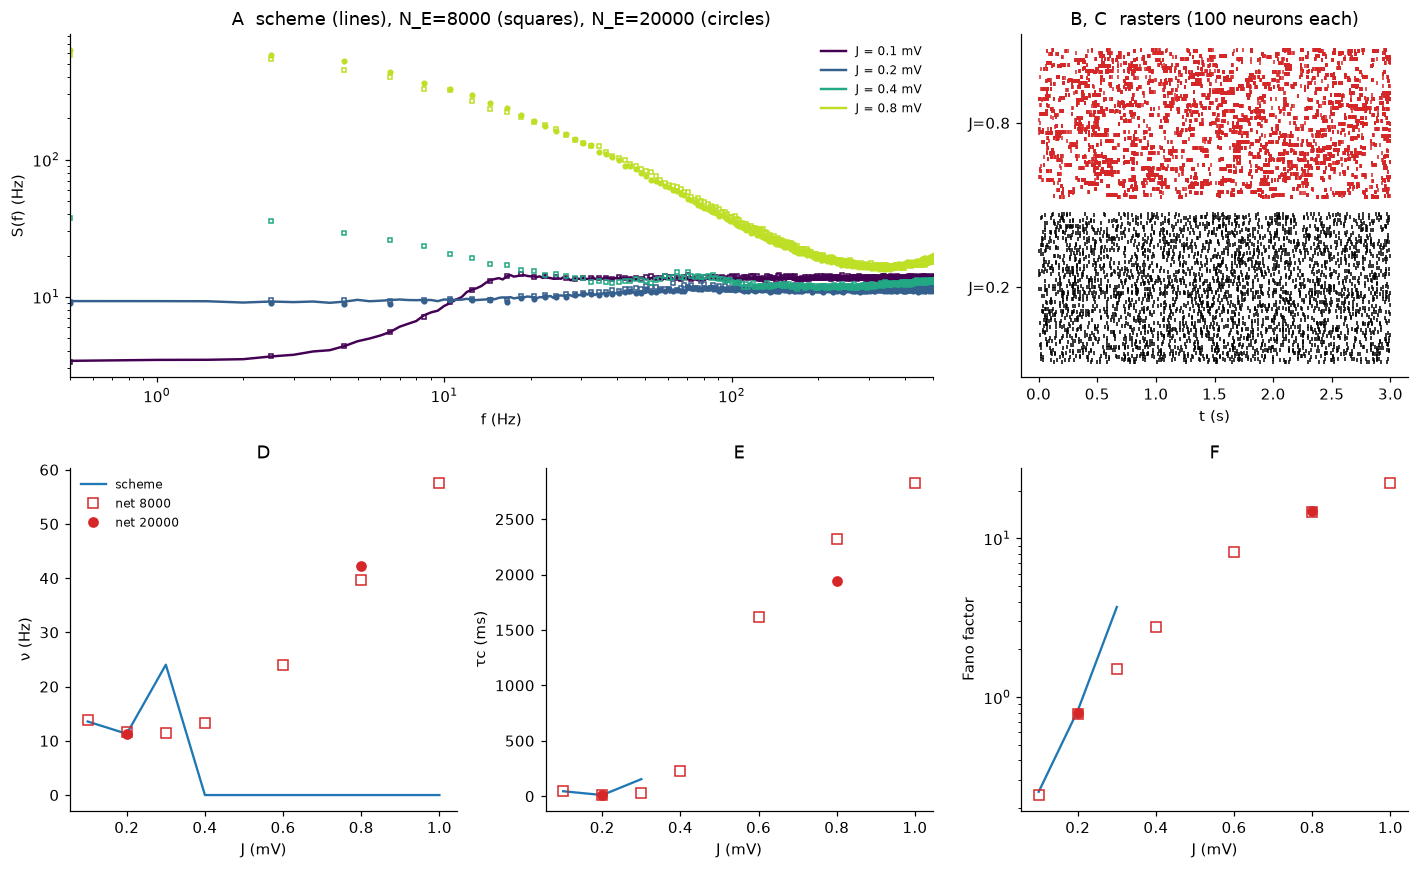

In [7]:
fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 3)
axA = fig.add_subplot(gs[0, 0:2])
cols = plt.cm.viridis(np.linspace(0, 0.9, len(J_SPECTRA)))
for c, J in zip(cols, J_SPECTRA):
    s, n = scheme[J], net_s[J]
    axA.loglog(s["f"], s["S_final"][0], color=c, lw=1.6, label=f"J = {J} mV")
    axA.loglog(n["f"][1::4], n["S_E"][1::4], "s", ms=3, mfc="none", color=c)
    if J in net_l:
        axA.loglog(net_l[J]["f"][1::4], net_l[J]["S_E"][1::4], "o", ms=3, color=c)
axA.set(xlim=(0.5, 500), xlabel="f (Hz)", ylabel="S(f) (Hz)",
        title=f"A  scheme (lines), N_E={N_E_SMALL} (squares), N_E={N_E_LARGE} (circles)")
axA.legend(frameon=False, fontsize=8)

for k, J in enumerate(LARGE_J):
    ax = fig.add_subplot(gs[0, 2]) if k == 0 else ax
    n = net_l[J]
    ids = {g: i for i, g in enumerate(np.unique(n["raster_i"]))}
    m = n["raster_t"] < 3.0
    y = np.array([ids[i] for i in n["raster_i"][m]]) + (0 if k == 0 else 110)
    ax.plot(n["raster_t"][m], y, "|", ms=2, color="k" if k == 0 else "tab:red")
ax.set(xlabel="t (s)", yticks=[50, 160], yticklabels=[f"J={LARGE_J[0]}", f"J={LARGE_J[1]}"],
       title="B, C  rasters (100 neurons each)")

def series(d, key):
    return np.array([float(np.ravel(d[J][key])[0]) for J in J_VALUES])
stats = [("nu", "nu_final", "nu_E", "ν (Hz)", 1), ("tau_c", "tau_c", "tau_c_E", "τc (ms)", 1e3),
         ("FF", "FF", "FF_E", "Fano factor", 1)]
for i, (lab, ks, kn, yl, sc) in enumerate(stats):
    ax = fig.add_subplot(gs[1, i])
    ax.plot(J_VALUES, series(scheme, ks) * sc, "-", color="tab:blue", label="scheme")
    ax.plot(J_VALUES, series(net_s, kn) * sc, "s", mfc="none", color="tab:red", label=f"net {N_E_SMALL}")
    ax.plot(LARGE_J, [float(net_l[J][kn]) * sc for J in LARGE_J], "o", color="tab:red", label=f"net {N_E_LARGE}")
    ax.set(xlabel="J (mV)", ylabel=yl, title="DEF"[i])
    if lab == "FF": ax.set_yscale("log")
fig.axes[-3].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "figure04_slow_fluctuations.png", dpi=200)
plt.show()

In [6]:
print(" J    nu_sch  nu_net   FF_sch  FF_net   tc_sch  tc_net (ms)")
for J in J_VALUES:
    s, n = scheme[J], net_s[J]
    print(f"{J:4.1f} {float(s['nu_final'][0]):7.2f} {float(n['nu_E']):7.2f}  {float(s['FF'][0]):7.2f} {float(n['FF_E']):7.2f}"
          f"  {1e3*float(s['tau_c'][0]):7.2f} {1e3*float(n['tau_c_E']):7.2f}")

 J    nu_sch  nu_net   FF_sch  FF_net   tc_sch  tc_net (ms)
 0.1   13.56   13.83     0.25    0.24    44.83   44.89
 0.2   11.30   11.67     0.82    0.78    10.53   12.97
 0.3   24.04   11.48     3.70    1.51   153.97   28.50
 0.4    0.00   13.29      nan    2.75      nan  225.67
 0.6    0.00   23.90      nan    8.20      nan 1617.59
 0.8    0.00   39.64      nan   14.68      nan 2316.59
 1.0    0.00   57.52      nan   22.28      nan 2824.48


## Notes

_Filled in after the run._